In [6]:
import pandas as pd                                          # tables
import numpy as np                                           # random shuffles, math
from sklearn.pipeline import make_pipeline                   # fill blanks -> model
from sklearn.impute import SimpleImputer                     # fills blanks
from sklearn.linear_model import LinearRegression            # our final model type
from sklearn.inspection import permutation_importance        # shuffle-one-feature importance

df = pd.read_parquet("../data/processed/features.parquet")   # feature set v2
df = df[(df["history_flag"] == "ok") & (df["is_upcoming"] == 0)]  # rows with history that were actually played

TARGET = "fantasy_points_ppr"                                # what we predict
ROLE_CUTOFF = 0.25                                           # real-role threshold (Decision 3)
POSITIONS = ["QB", "RB", "WR", "TE"]                         # one model each
ID_COLS = ["player_id", "player_display_name", "position", "team",   # identifiers, never model inputs
           "opponent_team", "season", "week", "history_flag", "is_upcoming"]
FEATURES = [c for c in df.columns if c not in ID_COLS + [TARGET]]    # the 26 features

tune_train = df[df["season"].between(2020, 2023)]            # learn on 2020-2023
tune_val = df[df["season"] == 2024]                          # measure importance on 2024 (never 2025)
print(len(FEATURES), "features")                             # check: 26

26 features


In [7]:
models, val_sets = {}, {}                                    # trained model + its 2024 rows, per position
for pos in POSITIONS:                                        # one model per position
    tr = tune_train[tune_train["position"] == pos]           # this position's 2020-2023 rows
    va = tune_val[(tune_val["position"] == pos) &            # this position's 2024 rows...
                  (tune_val["offense_pct_last3"] >= ROLE_CUTOFF)]  # ...real-role only (headline group)
    cols = [c for c in FEATURES if tr[c].notna().any()]      # skip all-blank features (EPA/att for non-QBs)
    model = make_pipeline(SimpleImputer(strategy="median", add_indicator=True),  # same setup as notebook 05
                          LinearRegression())
    model.fit(tr[cols], tr[TARGET])                          # train
    models[pos] = (model, cols)                              # keep the model and the columns it used
    val_sets[pos] = va                                       # keep its 2024 rows
    mae = (va[TARGET] - model.predict(va[cols])).abs().mean()  # baseline MAE before any shuffling
    print(f"{pos}: train {len(tr):,} | 2024 rows {len(va):,} | MAE {mae:.2f}")  # should match the 2024 check in nb 05

QB: train 2,246 | 2024 rows 519 | MAE 6.27
RB: train 5,420 | 2024 rows 858 | MAE 5.49
WR: train 8,698 | 2024 rows 1,748 | MAE 5.22
TE: train 4,234 | 2024 rows 964 | MAE 3.86


In [8]:
rows = []                                                    # one row per (position, feature)
for pos in POSITIONS:
    model, cols = models[pos]                                # this position's model and columns
    va = val_sets[pos]                                       # its 2024 rows
    result = permutation_importance(                         # shuffle each feature, re-predict, compare
        model, va[cols], va[TARGET],                         # model, inputs, actual points
        scoring="neg_mean_absolute_error",                   # measure damage in MAE (sklearn uses negative MAE)
        n_repeats=10, random_state=42)                       # shuffle 10 times each, same result every run
    for feat, mean, std in zip(cols, result.importances_mean, result.importances_std):  # walk through features
        rows.append({"position": pos, "feature": feat,       # which position and feature
                     "mae_increase": mean,                   # avg points of MAE added when shuffled
                     "std": std})                            # how much that varied across the 10 shuffles

imp = pd.DataFrame(rows)                                     # all results as one table
top10 = (imp.sort_values("mae_increase", ascending=False)    # most important first
            .groupby("position").head(10))                   # top 10 per position
top10.sort_values(["position", "mae_increase"],              # group by position, biggest first
                  ascending=[True, False]).round(3)          # show it

,position,feature,mae_increase,std
2,QB,fantasy_points_ppr_season,0.182,0.045
16,QB,rushing_yards_last3,0.164,0.042
10,QB,carry_share_last3,0.098,0.035
5,QB,carries_last3,0.091,0.045
4,QB,receptions_last3,0.088,0.022
22,QB,implied_total,0.079,0.034
6,QB,offense_pct_last3,0.069,0.036
19,QB,yards_per_carry_last3,0.047,0.019
15,QB,epa_per_att_last3,0.041,0.031
1,QB,fantasy_points_ppr_last3,0.034,0.019


In [9]:
GROUPS = {                                                   # every feature in exactly one group
    "history": ["fantasy_points_ppr_last1", "fantasy_points_ppr_last3", "fantasy_points_ppr_season"],
    "usage": ["targets_last3", "receptions_last3", "carries_last3", "offense_pct_last3",
              "target_share_last3", "air_yards_share_last3", "wopr_last3", "carry_share_last3",
              "attempts_last3"],                             # volume and role
    "production": ["passing_yards_last3", "passing_tds_last3", "passing_interceptions_last3",
                   "rushing_yards_last3"],                   # yards, TDs, interceptions
    "efficiency": ["epa_per_att_last3", "catch_rate_last3", "yards_per_catch_last3",
                   "yards_per_carry_last3"],                 # per-play quality
    "matchup_context": ["opp_ppr_allowed_avg", "team_att_avg", "implied_total",
                        "total_line", "is_home", "rest_days"],  # opponent, team, Vegas, schedule
}
assert sorted(sum(GROUPS.values(), [])) == sorted(FEATURES)  # check: every feature is in exactly one group

rng = np.random.default_rng(42)                              # random shuffler, fixed seed = repeatable
grows = []                                                   # one row per (position, group)
for pos in POSITIONS:
    model, cols = models[pos]                                # this position's model and columns
    va = val_sets[pos]                                       # its 2024 rows
    base_mae = (va[TARGET] - model.predict(va[cols])).abs().mean()  # MAE with nothing shuffled
    for group, feats in GROUPS.items():                      # one group at a time
        feats = [f for f in feats if f in cols]              # only features this position's model uses
        increases = []                                       # MAE increase for each of 10 shuffles
        for _ in range(10):                                  # repeat 10 times to average out luck
            X = va[cols].copy()                              # fresh copy of the 2024 inputs
            X[feats] = X[feats].values[rng.permutation(len(X))]  # shuffle the group's rows TOGETHER
            mae = (va[TARGET] - model.predict(X)).abs().mean()   # MAE with this group scrambled
            increases.append(mae - base_mae)                 # how much worse it got
        grows.append({"position": pos, "group": group,      # save the average damage
                      "mae_increase": np.mean(increases)})

group_imp = pd.DataFrame(grows)                              # all results as one table
group_imp.pivot(index="group", columns="position",           # rows = groups, columns = positions
                values="mae_increase").round(3)              # show it

position,QB,RB,TE,WR
group,,,,
efficiency,0.094,0.004,0.013,0.014
history,0.128,0.438,0.151,0.362
matchup_context,0.167,0.085,0.041,0.016
production,0.155,0.299,0.002,-0.002
usage,0.157,0.446,0.987,1.023


In [10]:
imp.to_csv("../reports/tables/feature_importance.csv", index=False)       # every feature, every position
group_imp.to_csv("../reports/tables/group_importance.csv", index=False)   # every group, every position
print("Saved feature_importance.csv and group_importance.csv")            # confirm

Saved feature_importance.csv and group_importance.csv


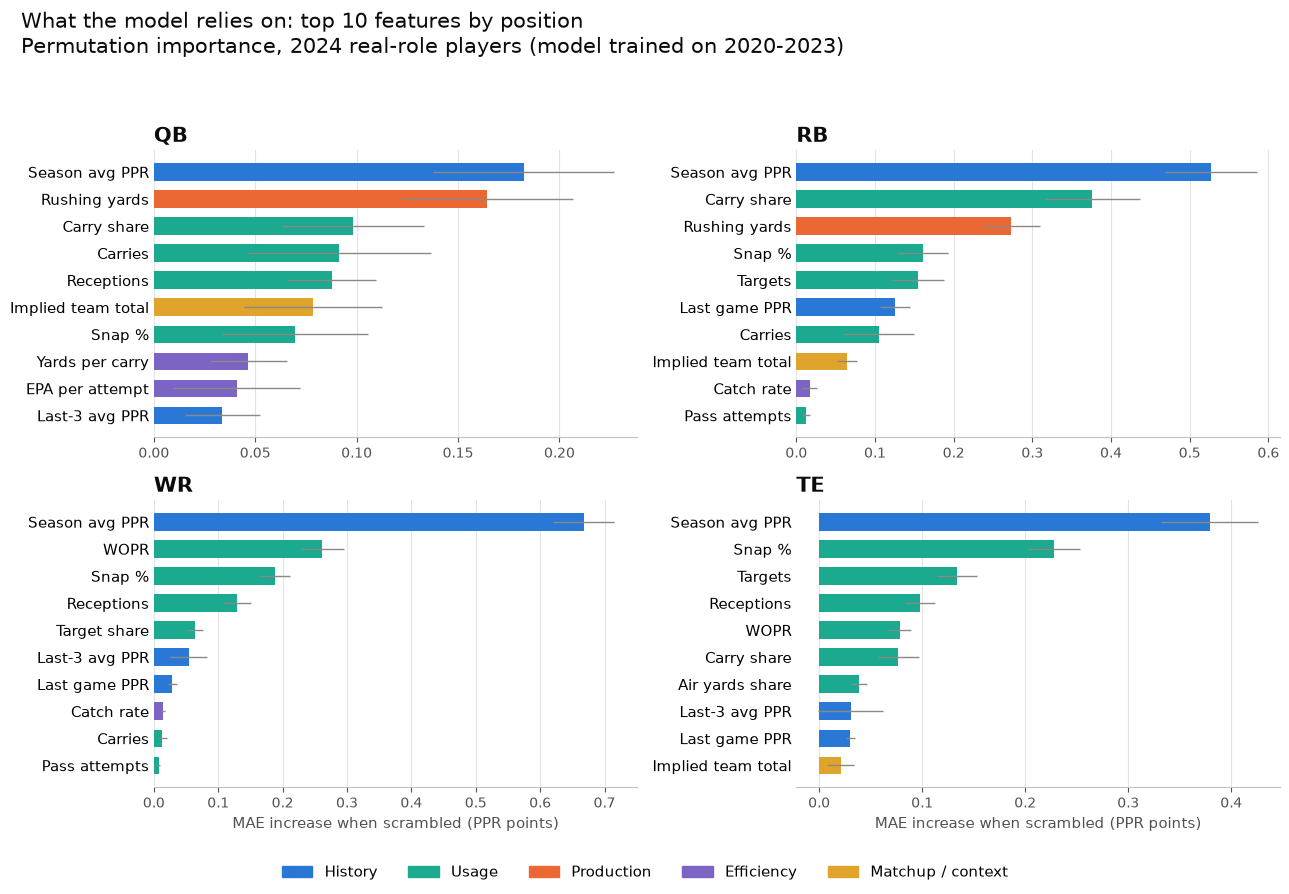

In [11]:
import matplotlib.pyplot as plt                                    # plotting

GROUP_OF = {f: g for g, feats in GROUPS.items() for f in feats}    # look up each feature's group
COLORS = {"history": "#2a78d6", "usage": "#1baa8f", "production": "#eb6834",   # one color per group
          "efficiency": "#7c64c4", "matchup_context": "#e0a32b"}
NICE = {"fantasy_points_ppr_season": "Season avg PPR", "fantasy_points_ppr_last3": "Last-3 avg PPR",   # readable labels
        "fantasy_points_ppr_last1": "Last game PPR", "offense_pct_last3": "Snap %",
        "targets_last3": "Targets", "receptions_last3": "Receptions", "carries_last3": "Carries",
        "target_share_last3": "Target share", "air_yards_share_last3": "Air yards share",
        "wopr_last3": "WOPR", "carry_share_last3": "Carry share", "attempts_last3": "Pass attempts",
        "passing_yards_last3": "Passing yards", "passing_tds_last3": "Passing TDs",
        "passing_interceptions_last3": "Interceptions", "epa_per_att_last3": "EPA per attempt",
        "rushing_yards_last3": "Rushing yards", "catch_rate_last3": "Catch rate",
        "yards_per_catch_last3": "Yards per catch", "yards_per_carry_last3": "Yards per carry",
        "team_att_avg": "Team pass attempts", "opp_ppr_allowed_avg": "Opponent PPR allowed",
        "implied_total": "Implied team total", "total_line": "Game total", "is_home": "Home game",
        "rest_days": "Rest days"}

fig, axes = plt.subplots(2, 2, figsize=(13, 9))                    # 2x2 grid, one panel per position
for ax, pos in zip(axes.flat, ["QB", "RB", "WR", "TE"]):           # fill each panel
    t = (imp[imp["position"] == pos]                               # this position's features
           .nlargest(10, "mae_increase")                           # its top 10
           .iloc[::-1])                                            # reverse so the biggest ends up on top
    colors = [COLORS[GROUP_OF[f]] for f in t["feature"]]           # bar color = feature group
    ax.barh([NICE[f] for f in t["feature"]], t["mae_increase"],    # horizontal bars, readable names
            xerr=t["std"], color=colors, height=0.65,              # error bar = std across the 10 shuffles
            error_kw={"ecolor": "#8a8984", "lw": 1}, zorder=3)     # thin gray error bars, drawn above grid
    ax.set_title(pos, fontsize=15, loc="left", fontweight="bold", color="#0b0b0b")  # panel title
    ax.tick_params(axis="y", labelsize=11, length=0)               # feature names, no tick marks
    ax.tick_params(axis="x", labelsize=10, colors="#52514e")       # x numbers in gray
    ax.grid(axis="x", color="#e4e3df", linewidth=0.8, zorder=0)    # faint vertical gridlines
    for side in ["top", "right", "left"]:                          # remove 3 box edges
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")                       # light axis line at 0

for ax in axes[1]:                                                 # bottom row only
    ax.set_xlabel("MAE increase when scrambled (PPR points)", fontsize=11, color="#52514e")  # what the x-axis means

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS.values()]   # legend color swatches
labels = ["History", "Usage", "Production", "Efficiency", "Matchup / context"]  # legend names (same order)
fig.legend(handles, labels, loc="lower center", ncol=5, frameon=False, fontsize=11)   # one legend for all panels
fig.suptitle("What the model relies on: top 10 features by position\n"             # title states the point
             "Permutation importance, 2024 real-role players (model trained on 2020-2023)",
             fontsize=15, x=0.02, ha="left", color="#0b0b0b")
fig.tight_layout(rect=[0, 0.05, 1, 0.94])                          # leave room for legend and title
fig.savefig("../reports/figures/feature_importance_top10.png",     # save for the poster (checkpoint 5)
            dpi=200, bbox_inches="tight", facecolor="white")
plt.show()                                                         # show in the notebook